<a href="https://colab.research.google.com/github/ayushsharma0130/Statistics-Practicals/blob/main/Practical1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import ttest_ind, chi2_contingency

# Load dataset
data = pd.read_csv("/content/evalsdataset.csv")

# Display first five rows
print("First Five Rows:")
print(data.head())

# Display shape
print("\nDataset Shape:")
print(data.shape)

# Display columns
print("\nDataset Columns:")
print(data.columns)

# Dataset information
print("\nDataset Information:")
data.info()

First Five Rows:
   course_id  prof_id  score          rank     ethnicity  gender language  \
0          1        1    4.7  tenure track      minority  female  english   
1          2        1    4.1  tenure track      minority  female  english   
2          3        1    3.9  tenure track      minority  female  english   
3          4        1    4.8  tenure track      minority  female  english   
4          5        2    4.6       tenured  not minority    male  english   

   age  cls_perc_eval  cls_did_eval  ...   cls_credits bty_f1lower  \
0   36       55.81395            24  ...  multi credit           5   
1   36       68.80000            86  ...  multi credit           5   
2   36       60.80000            76  ...  multi credit           5   
3   36       62.60163            77  ...  multi credit           5   
4   59       85.00000            17  ...  multi credit           4   

  bty_f1upper bty_f2upper  bty_m1lower  bty_m1upper  bty_m2upper  bty_avg  \
0           7         

**Q1. Identify whether the Teachers' Ratings dataset is time series or cross-sectional.**

In [2]:
print("Q1. Type of Dataset")

print("The Teachers' Ratings dataset is Cross-Sectional Data.")

print("Reason: It contains observations about different professors")
print("and their courses rather than tracking the same professors")
print("over multiple time periods.")

Q1. Type of Dataset
The Teachers' Ratings dataset is Cross-Sectional Data.
Reason: It contains observations about different professors
and their courses rather than tracking the same professors
over multiple time periods.


**Q2. Find the mean, median, minimum and maximum values for students.
We use the cls_students column, which represents the number of students in each course.**

In [3]:
students = data["cls_students"]

print("Q2. Students Statistics")

print("Mean:", students.mean())
print("Median:", students.median())
print("Minimum:", students.min())
print("Maximum:", students.max())

Q2. Students Statistics
Mean: 55.177105831533474
Median: 29.0
Minimum: 8
Maximum: 581


**Conclusion: The average number of students per course is approximately 55.18. The median is 29 students, the minimum is 8, and the maximum is 581 students.**

##**Q3. Produce the descriptive statistics table.**

In [4]:
print("Q3. Descriptive Statistics")

print(data.describe())
print(data.describe(include="all"))

Q3. Descriptive Statistics
        course_id     prof_id       score         age  cls_perc_eval  \
count  463.000000  463.000000  463.000000  463.000000     463.000000   
mean   232.000000   45.153348    4.174730   48.365011      74.427788   
std    133.800847   27.547052    0.543865    9.802742      16.756311   
min      1.000000    1.000000    2.300000   29.000000      10.416670   
25%    116.500000   20.000000    3.800000   42.000000      62.696165   
50%    232.000000   43.000000    4.300000   48.000000      76.923080   
75%    347.500000   70.500000    4.600000   57.000000      87.249170   
max    463.000000   94.000000    5.000000   73.000000     100.000000   

       cls_did_eval  cls_students  bty_f1lower  bty_f1upper  bty_f2upper  \
count    463.000000    463.000000   463.000000   463.000000   463.000000   
mean      36.624190     55.177106     3.963283     5.019438     5.213823   
std       45.018481     75.072800     1.873936     1.934437     2.018224   
min        5.000000 

**Conclusion: The descriptive statistics table provides information about the count, mean, standard deviation, minimum, maximum, and quartiles of numerical variables. It helps us understand the overall distribution and characteristics of the dataset.**

##**Q4. Create a histogram of the beauty variable and briefly comment on the distribution.**

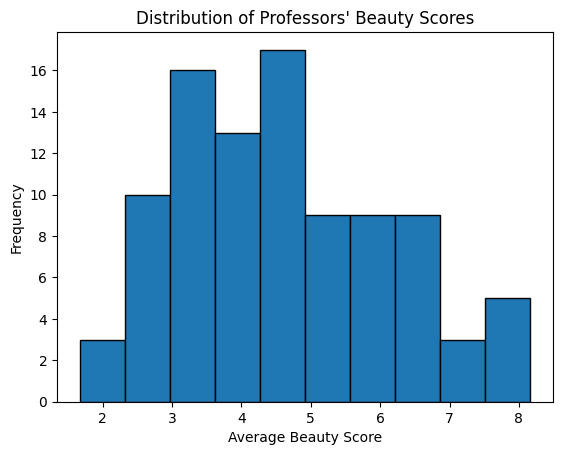

In [5]:
# Keep one observation for each professor
prof_data = data.drop_duplicates(subset="prof_id")

# Create histogram
plt.hist(prof_data["bty_avg"], bins=10, edgecolor="black")

plt.xlabel("Average Beauty Score")
plt.ylabel("Frequency")
plt.title("Distribution of Professors' Beauty Scores")

plt.show()

**Conclusion: The histogram shows the distribution of professors' average beauty scores. Most scores are concentrated around the middle values, while fewer professors have very high or very low scores. The distribution is slightly positively skewed (right-skewed).**

##**Q5. Does average beauty score differ by gender? Produce the means and standard deviations for both male and female instructors.**

In [6]:
# One observation per professor
prof_data = data.drop_duplicates(subset="prof_id")

print("Q5. Average Beauty Score by Gender")

gender_stats = prof_data.groupby("gender")["bty_avg"].agg(
    ["count", "mean", "std"]
)

print(gender_stats)

Q5. Average Beauty Score by Gender
        count      mean       std
gender                           
female     40  4.924975  1.622444
male       54  4.357963  1.545066


In [7]:
male = prof_data[prof_data["gender"] == "male"]["bty_avg"]

female = prof_data[prof_data["gender"] == "female"]["bty_avg"]

t_stat, p_value = ttest_ind(male, female)

print("T-statistic:", t_stat)
print("P-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("Beauty score differs significantly by gender.")
else:
    print("Fail to reject H0")
    print("Beauty score does not differ significantly by gender.")

T-statistic: -1.7220954306134912
P-value: 0.08841268891710281
Fail to reject H0
Beauty score does not differ significantly by gender.


**Conclusion: Female instructors have a higher average beauty score (4.925) than male instructors (4.358). However, the p-value is 0.0884, which is greater than 0.05. Therefore, the difference is not statistically significant.**

##**Q6. Calculate the percentage of males and females that are tenured professors. Does tenure status differ by gender?**

In [8]:
# Keep one observation per professor
prof_data = data.drop_duplicates(subset="prof_id").copy()

# Create tenure status column
prof_data["Tenure_Status"] = np.where(
    prof_data["rank"] == "tenured",
    "Tenured",
    "Not Tenured"
)

# Create contingency table
tenure_table = pd.crosstab(
    prof_data["gender"],
    prof_data["Tenure_Status"]
)

print("Number of Professors:")
print(tenure_table)

Number of Professors:
Tenure_Status  Not Tenured  Tenured
gender                             
female                  22       18
male                    18       36


In [9]:
percentage = pd.crosstab(
    prof_data["gender"],
    prof_data["Tenure_Status"],
    normalize="index"
) * 100

print("Percentage of Tenured and Non-Tenured Professors:")
print(percentage.round(2))

Percentage of Tenured and Non-Tenured Professors:
Tenure_Status  Not Tenured  Tenured
gender                             
female               55.00    45.00
male                 33.33    66.67


In [10]:
chi2, p_value, dof, expected = chi2_contingency(tenure_table)

print("Chi-Square Statistic:", chi2)
print("P-value:", p_value)
print("Degrees of Freedom:", dof)

alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("Tenure status differs significantly by gender.")
else:
    print("Fail to reject H0")
    print("No significant association between gender and tenure status.")

Chi-Square Statistic: 3.570956361454047
P-value: 0.05879843857331395
Degrees of Freedom: 1
Fail to reject H0
No significant association between gender and tenure status.


**Hypotheses:
H0: There is no association between gender and tenure status.

H1: There is an association between gender
and tenure status.

Conclusion: 66.67% of male professors and 45% of female professors are tenured. Although the percentage is higher for males, the p-value (0.0588) is greater than 0.05. Therefore, we fail to reject the null hypothesis. There is not enough statistical evidence to conclude that tenure status differs significantly by gender.**